HOUSE RENT (MULTIPLE LINEAR REGRESSION) part 1.1v(selected features and LOG OF RENT)

Data extraction , EDA and Data Processing

In [3]:
import numpy as np
import pandas as pd 
import matplotlib.pyplot as plt
import seaborn as sns
import warnings
warnings.filterwarnings("ignore")

In [4]:
whole=pd.read_csv("House_Rent_Dataset.csv")

In [5]:
whole.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 4746 entries, 0 to 4745
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   Posted On          4746 non-null   object
 1   BHK                4746 non-null   int64 
 2   Rent               4746 non-null   int64 
 3   Size               4746 non-null   int64 
 4   Floor              4746 non-null   object
 5   Area Type          4746 non-null   object
 6   Area Locality      4746 non-null   object
 7   City               4746 non-null   object
 8   Furnishing Status  4746 non-null   object
 9   Tenant Preferred   4746 non-null   object
 10  Bathroom           4746 non-null   int64 
 11  Point of Contact   4746 non-null   object
dtypes: int64(4), object(8)
memory usage: 445.1+ KB


In [6]:
whole

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact
0,2022-05-18,2,10000,1100,Ground out of 2,Super Area,Bandel,Kolkata,Unfurnished,Bachelors/Family,2,Contact Owner
1,2022-05-13,2,20000,800,1 out of 3,Super Area,"Phool Bagan, Kankurgachi",Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
2,2022-05-16,2,17000,1000,1 out of 3,Super Area,Salt Lake City Sector 2,Kolkata,Semi-Furnished,Bachelors/Family,1,Contact Owner
3,2022-07-04,2,10000,800,1 out of 2,Super Area,Dumdum Park,Kolkata,Unfurnished,Bachelors/Family,1,Contact Owner
4,2022-05-09,2,7500,850,1 out of 2,Carpet Area,South Dum Dum,Kolkata,Unfurnished,Bachelors,1,Contact Owner
...,...,...,...,...,...,...,...,...,...,...,...,...
4741,2022-05-18,2,15000,1000,3 out of 5,Carpet Area,Bandam Kommu,Hyderabad,Semi-Furnished,Bachelors/Family,2,Contact Owner
4742,2022-05-15,3,29000,2000,1 out of 4,Super Area,"Manikonda, Hyderabad",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Owner
4743,2022-07-10,3,35000,1750,3 out of 5,Carpet Area,"Himayath Nagar, NH 7",Hyderabad,Semi-Furnished,Bachelors/Family,3,Contact Agent
4744,2022-07-06,3,45000,1500,23 out of 34,Carpet Area,Gachibowli,Hyderabad,Semi-Furnished,Family,2,Contact Agent


In [8]:
whole["Rent_per_sqft"] = whole["Rent"] / whole["Size"]
whole.groupby("City")["Rent_per_sqft"].agg(
    ["count", "mean", "median", "std"]
)

,count,mean,median,std
City,,,,
Bangalore,886,21.751740,17.500000,47.911811
Chennai,891,19.785751,16.216216,23.885343
Delhi,605,67.631495,28.571429,90.467248
Hyderabad,868,23.585529,14.545455,70.550080
Kolkata,524,16.491473,13.315603,19.565843
Mumbai,972,81.668894,71.428571,41.495356


<Axes: xlabel='Rent_per_sqft'>

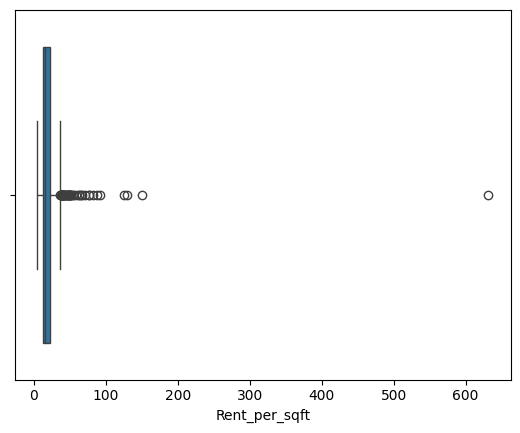

In [9]:
sns.boxplot(x=whole[(whole["City"]=="Chennai") ]["Rent_per_sqft"])


Text(0.5, 1.0, 'Bangalore')

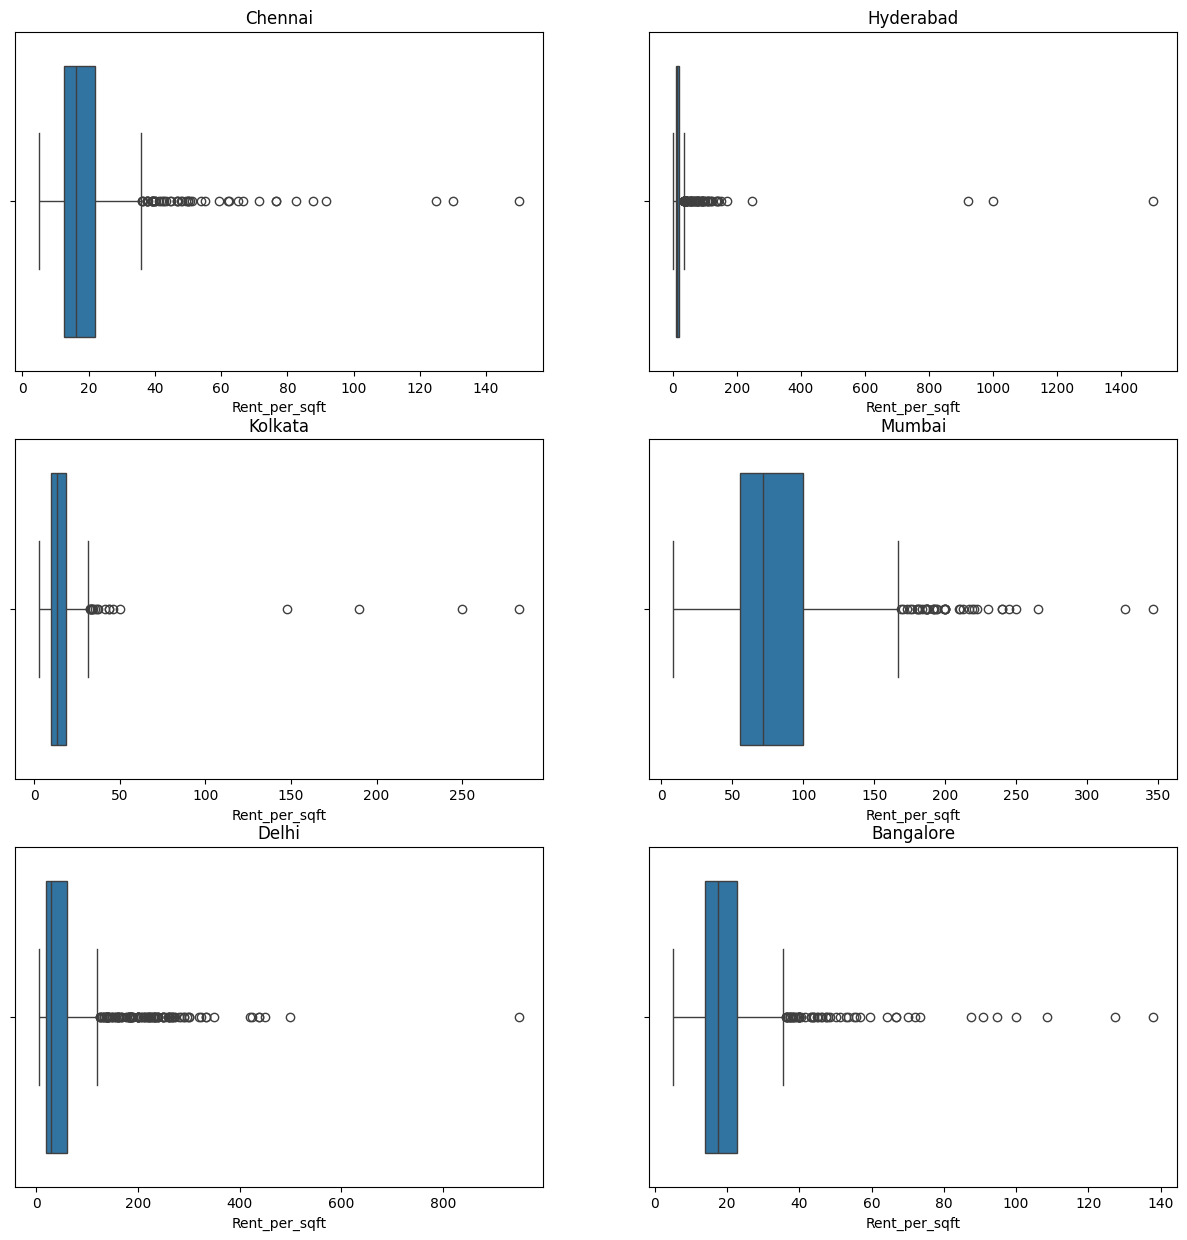

In [10]:
fig ,axes=plt.subplots(3,2,figsize=(15,15))

sns.boxplot(x=whole[(whole["City"]=="Chennai") & (whole["Rent_per_sqft"]<600)]["Rent_per_sqft"] ,ax=axes[0,0])
axes[0,0].set_title("Chennai")
sns.boxplot(x=whole[whole["City"]=="Hyderabad"]["Rent_per_sqft"] ,ax=axes[0,1])
axes[0,1].set_title("Hyderabad")
sns.boxplot(x=whole[whole["City"]=="Kolkata"]["Rent_per_sqft"] ,ax=axes[1,0])
axes[1,0].set_title("Kolkata")
sns.boxplot(x=whole[whole["City"]=="Mumbai"]["Rent_per_sqft"] ,ax=axes[1,1])
axes[1,1].set_title("Mumbai")
sns.boxplot(x=whole[whole["City"]=="Delhi"]["Rent_per_sqft"] ,ax=axes[2,0])
axes[2,0].set_title("Delhi")
sns.boxplot(x=whole[(whole["City"]=="Bangalore") & (whole["Rent_per_sqft"]<1200) ]["Rent_per_sqft"] ,ax=axes[2,1])
axes[2,1].set_title("Bangalore")

In [11]:
whole[(whole["City"]=="Chennai") & (whole["Rent_per_sqft"]>600)]

,Posted On,BHK,Rent,Size,Floor,Area Type,Area Locality,City,Furnishing Status,Tenant Preferred,Bathroom,Point of Contact,Rent_per_sqft
3656,2022-07-06,2,600000,950,1 out of 1,Carpet Area,Vettuvankeni,Chennai,Unfurnished,Bachelors,2,Contact Owner,631.578947


In [12]:
whole.iloc[3656]


Posted On               2022-07-06
BHK                              2
Rent                        600000
Size                           950
Floor                   1 out of 1
Area Type              Carpet Area
Area Locality         Vettuvankeni
City                       Chennai
Furnishing Status      Unfurnished
Tenant Preferred         Bachelors
Bathroom                         2
Point of Contact     Contact Owner
Rent_per_sqft           631.578947
Name: 3656, dtype: object

In [13]:
whole.drop(index=3656,inplace=True) #already

<Axes: xlabel='Rent_per_sqft'>

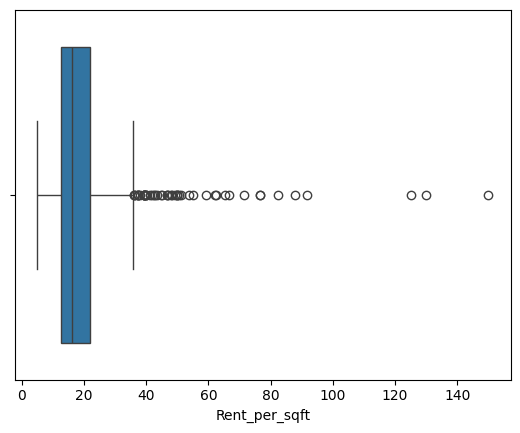

In [14]:
sns.boxplot(x=whole[(whole["City"]=="Chennai") ]["Rent_per_sqft"])

In [15]:
whole_chennai=whole[whole["City"]=="Chennai"]

feature extraction

In [17]:
df=whole_chennai[["BHK","Size","Floor","Furnishing Status","Bathroom","Rent"]]
df.describe()
df.info()
df.shape

<class 'pandas.core.frame.DataFrame'>
Index: 890 entries, 2987 to 3877
Data columns (total 6 columns):
 #   Column             Non-Null Count  Dtype 
---  ------             --------------  ----- 
 0   BHK                890 non-null    int64 
 1   Size               890 non-null    int64 
 2   Floor              890 non-null    object
 3   Furnishing Status  890 non-null    object
 4   Bathroom           890 non-null    int64 
 5   Rent               890 non-null    int64 
dtypes: int64(4), object(2)
memory usage: 48.7+ KB


(890, 6)

In [18]:
df

,BHK,Size,Floor,Furnishing Status,Bathroom,Rent
2987,2,1100,1 out of 2,Semi-Furnished,2,15000
2988,2,1000,Ground out of 1,Semi-Furnished,2,6500
2989,3,2400,1 out of 3,Semi-Furnished,3,90000
2990,3,3000,1 out of 1,Furnished,4,200000
2991,1,650,Ground out of 2,Semi-Furnished,1,15000
...,...,...,...,...,...,...
3873,3,1050,5 out of 10,Semi-Furnished,3,28000
3874,2,800,5 out of 6,Semi-Furnished,2,10677
3875,3,1625,8 out of 11,Furnished,3,50000
3876,3,1535,1 out of 2,Unfurnished,3,32500


In [19]:
df = df.sample(frac=1, random_state=42)

In [20]:
df["Furnishing Status"] = df["Furnishing Status"].map({"Unfurnished": 0, "Semi-Furnished": 1, "Furnished": 2})
df.head()

,BHK,Size,Floor,Furnishing Status,Bathroom,Rent
3267,2,650,2 out of 2,2,2,17500
3421,3,1300,19 out of 19,2,3,30000
3026,2,850,Ground out of 2,0,2,12000
3404,1,500,1 out of 4,0,1,18000
3572,2,1000,1 out of 2,0,2,18000


In [21]:
df['Total_Floors']=df["Floor"].str.extract(r"out of\s*(\d+)")[0].astype(float)

In [22]:
df['Floor_no.']=df["Floor"].str.extract(r"^(\d+)")

In [23]:
df["Floor_no."].value_counts()

Floor_no.
1     321
2     164
3      59
4      30
9      13
5      11
7      10
8       7
10      6
15      6
11      6
6       5
12      3
17      2
19      2
20      1
16      1
25      1
13      1
24      1
28      1
14      1
Name: count, dtype: int64

In [24]:
df.loc[df["Floor"].str.startswith("Ground", na=False),"Floor_no."] = 0

df.loc[df["Floor"].str.startswith("Upper Basement", na=False),"Floor_no."] = -1

df.loc[df["Floor"].str.startswith("Lower Basement", na=False),"Floor_no."] = -2

In [25]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 890 entries, 3267 to 3089
Data columns (total 8 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   BHK                890 non-null    int64  
 1   Size               890 non-null    int64  
 2   Floor              890 non-null    object 
 3   Furnishing Status  890 non-null    int64  
 4   Bathroom           890 non-null    int64  
 5   Rent               890 non-null    int64  
 6   Total_Floors       890 non-null    float64
 7   Floor_no.          890 non-null    object 
dtypes: float64(1), int64(5), object(2)
memory usage: 62.6+ KB


In [26]:
df["Floor_no."] = df["Floor_no."].astype(float)

In [27]:
df.drop(columns=["Floor"],inplace=True)

In [28]:
df[df["Floor_no."]==-1].value_counts()

BHK  Size  Furnishing Status  Bathroom  Rent  Total_Floors  Floor_no.
1    400   0                  1         8000  2.0           -1.0         1
Name: count, dtype: int64

In [29]:
cols = df.columns.tolist()
cols.remove('Rent')
cols.append('Rent')

df = df[cols]
df.head()

,BHK,Size,Furnishing Status,Bathroom,Total_Floors,Floor_no.,Rent
3267,2,650,2,2,2.0,2.0,17500
3421,3,1300,2,3,19.0,19.0,30000
3026,2,850,0,2,2.0,0.0,12000
3404,1,500,0,1,4.0,1.0,18000
3572,2,1000,0,2,2.0,1.0,18000


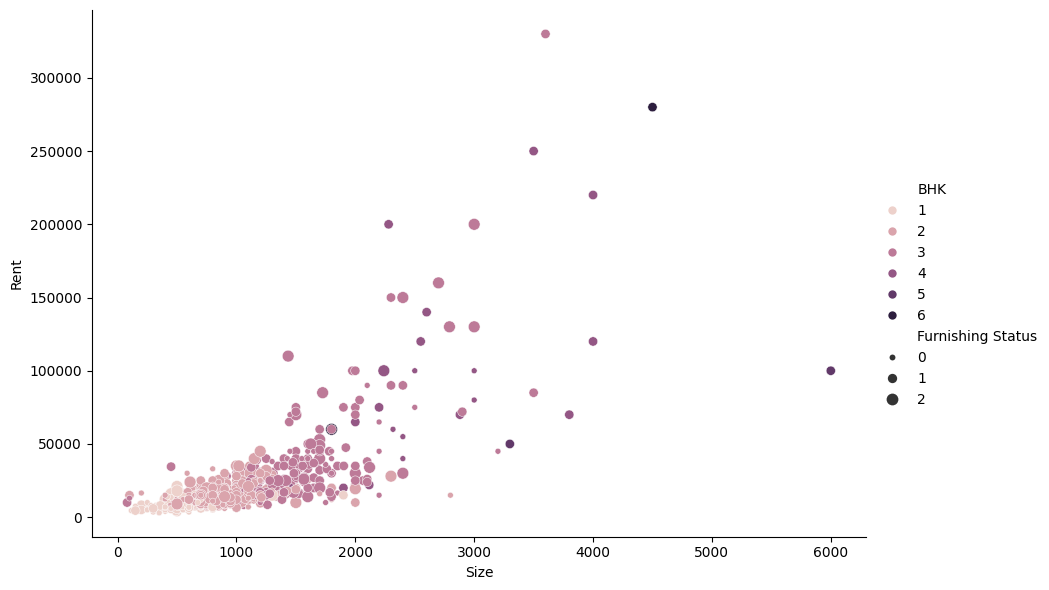

In [31]:
sns.relplot(kind="scatter",data=df,x='Size',y='Rent',hue='BHK',size='Furnishing Status',height=6,aspect=1.5)

<Axes: xlabel='BHK', ylabel='Rent'>

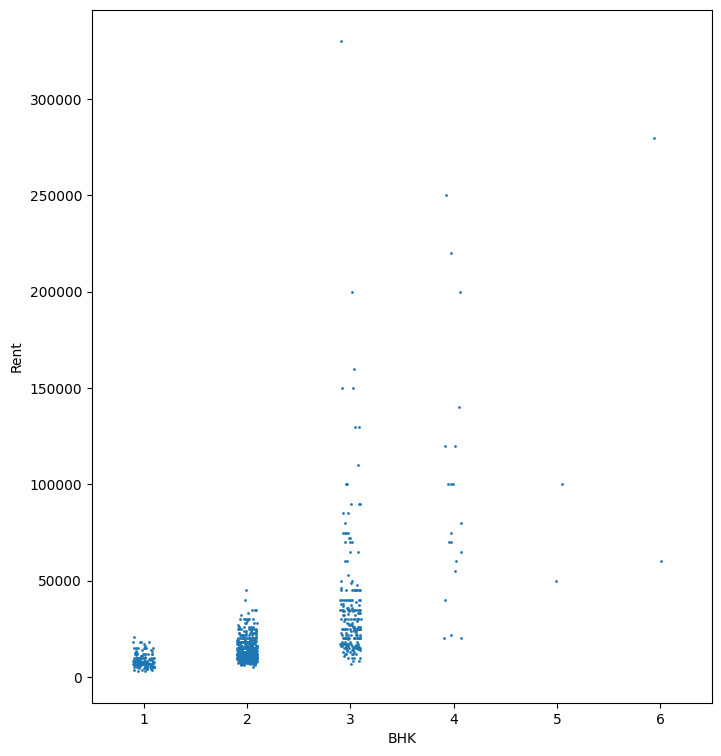

In [33]:
plt.figure(figsize=(8, 9))
sns.stripplot(data=df,x='BHK',y='Rent',size=2)

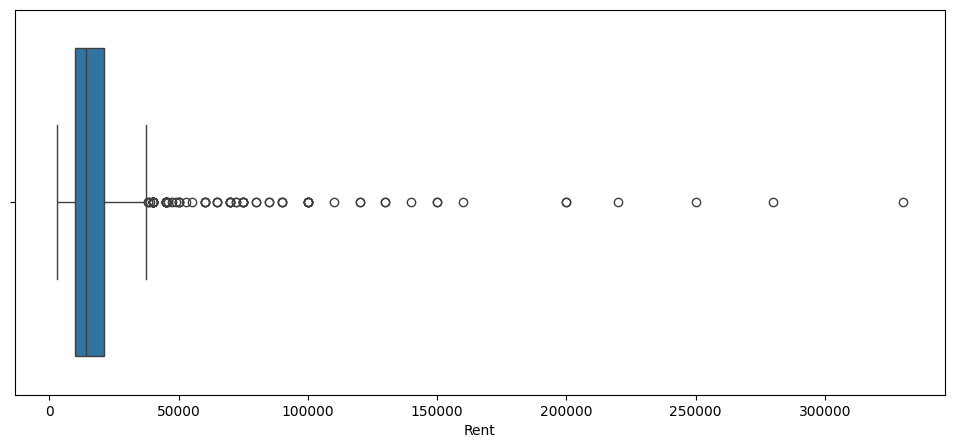

In [34]:
plt.figure(figsize=(12, 5))

sns.boxplot(x=df["Rent"])

plt.show()

<Axes: >

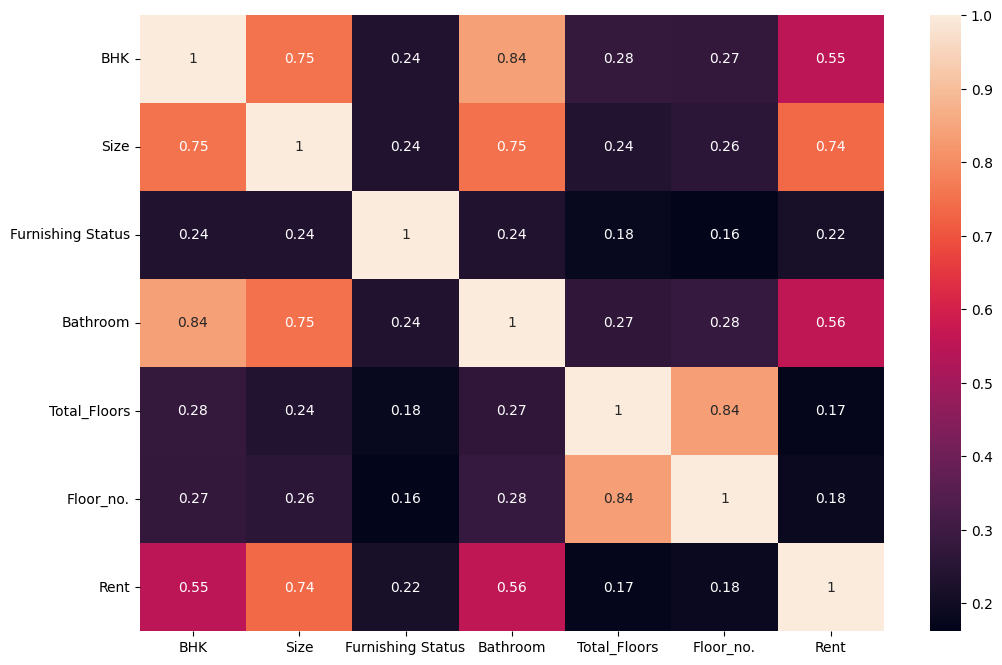

In [38]:
plt.figure(figsize=(12,8))
sns.heatmap(df.corr(numeric_only=True), annot=True)

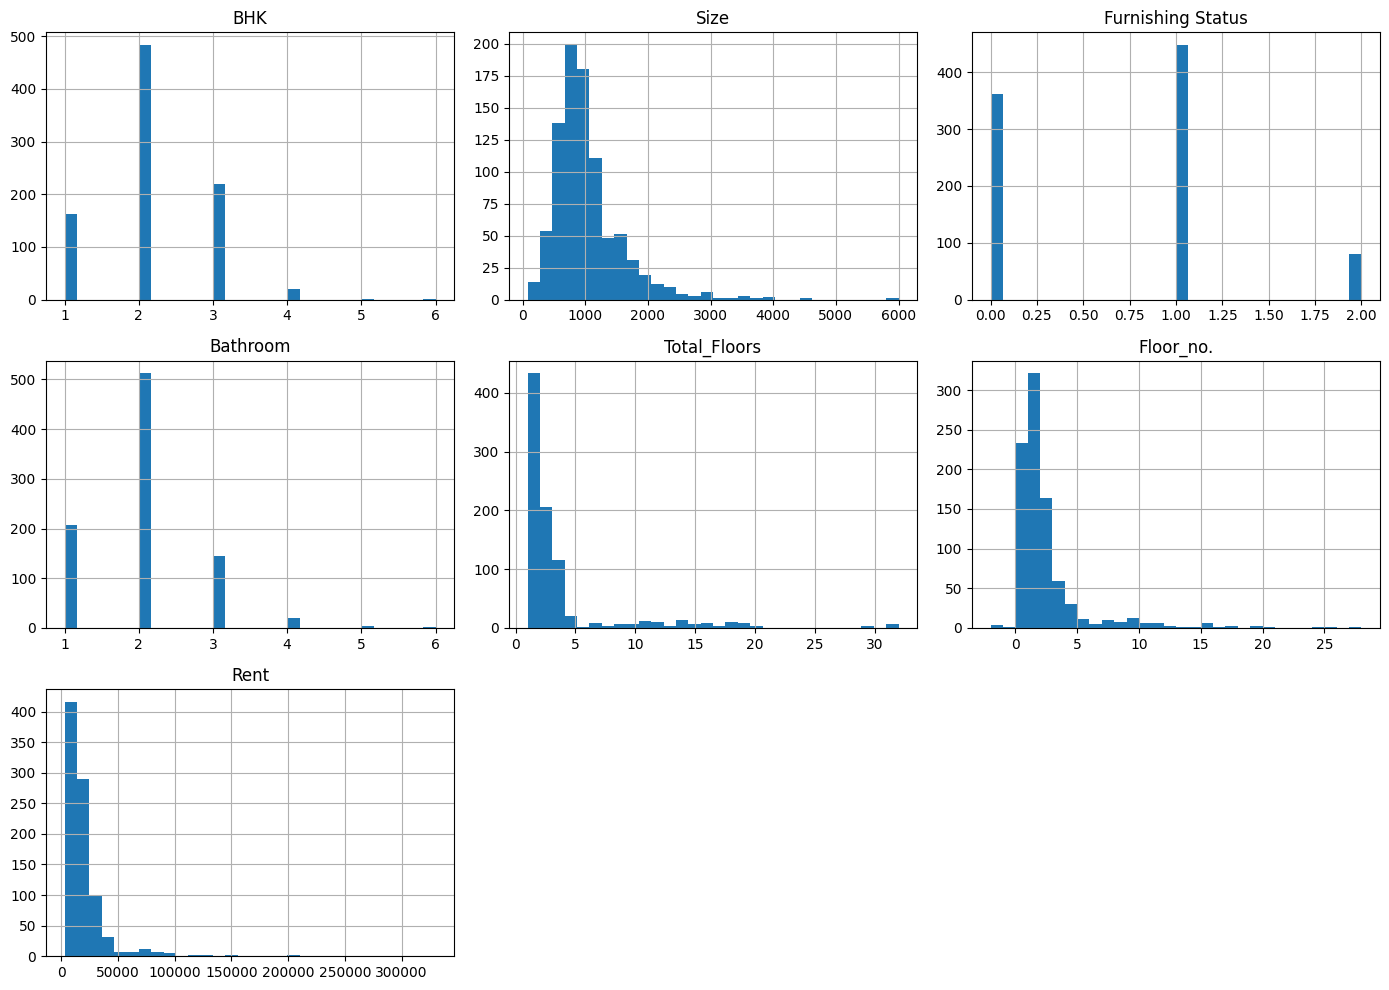

In [39]:
df.hist(figsize=(14, 10), bins=30)

plt.tight_layout()

plt.show()

In [40]:
df_c=df[df["Rent"]<100000]

In [42]:
# Find the split point

split = int(0.8 * len(df_c))

# Split

train_df = df_c.iloc[:split]

test_df = df_c.iloc[split:]

In [43]:

X_train, y_train = train_df .drop("Rent" ,axis=1), train_df["Rent"]
X_test,  y_test  = test_df.drop("Rent",axis=1), test_df["Rent"]


In [50]:
#import numpy as np

# ---------- NEW: log-transform the target ----------
y_train_log = np.log(y_train)   # CHANGED
y_test_log  = np.log(y_test)    # CHANGED

# ----------  Z-score scaling (stats from TRAIN only) ----------
mu = X_train.mean(axis=0)
sigma = X_train.std(axis=0)

X_train_s = (X_train - mu) / sigma
X_test_s = (X_test - mu) / sigma

# ----------  Gradient descent ----------
def gradient_descent(x, y, lr=0.01, epochs=2500):
    n_features = x.shape[1]
    w = np.zeros(n_features)
    b = 0
    m = len(x)

    history = []
    for i in range(epochs):
        y_pred = np.dot(x, w) + b
        error = y_pred - y
        dw = (1 / m) * np.dot(x.T, error)
        db = (1 / m) * np.sum(error)

        w -= lr * dw
        b -= lr * db
        history.append((1 / (2 * m)) * np.sum(error ** 2))
        if i % 200 == 0:
            print(f"epoch {i:4d}  cost = {history[-1]:.6f}")   # CHANGED: cost is now small, need more decimals
    return w, b, history

w, b, cost_history = gradient_descent(X_train_s, y_train_log)   # CHANGED: train on log(rent)

print(f"\nLearned weights (scaled space):")
print(w)
print(f"Bias (scaled space): {b:.4f}")                          # CHANGED: bias is ~9-10 now

w_orig = w / sigma
b_orig = b - np.sum(w * mu / sigma)
print("In original units (effect on log-rent):")
print("w =\n", w_orig)
print("b =", b_orig)

# ----------  Evaluation metrics ----------
def evaluate(y_true, y_pred):
    mse  = np.mean((y_true - y_pred) ** 2)
    rmse = np.sqrt(mse)
    mae  = np.mean(np.abs(y_true - y_pred))
    ss_res = np.sum((y_true - y_pred) ** 2)
    ss_tot = np.sum((y_true - y_true.mean()) ** 2)
    r2 = 1 - ss_res / ss_tot
    return mse, rmse, mae, r2

# CHANGED: predictions are in log space, convert back with exp
train_pred_log = np.dot(X_train_s, w) + b
test_pred_log  = np.dot(X_test_s, w) + b
train_pred = np.exp(train_pred_log)
test_pred  = np.exp(test_pred_log)

print("\n--- Rupee scale (compare with your old 8873 RMSE / 6047 MAE) ---")
for name, yt, yp in [("Train", y_train, train_pred), ("Test", y_test, test_pred)]:
    mse, rmse, mae, r2 = evaluate(yt, yp)
    print(f"{name}: MSE={mse:.1f}  RMSE={rmse:.1f}  MAE={mae:.1f}  R2={r2:.4f}")

print("\n--- Log scale ---")
for name, yt, yp in [("Train", y_train_log, train_pred_log), ("Test", y_test_log, test_pred_log)]:
    mse, rmse, mae, r2 = evaluate(yt, yp)
    print(f"{name}: RMSE={rmse:.4f}  MAE={mae:.4f}  R2={r2:.4f}")

epoch    0  cost = 46.224117
epoch  200  cost = 0.892171
epoch  400  cost = 0.079841
epoch  600  cost = 0.065060
epoch  800  cost = 0.064719
epoch 1000  cost = 0.064683
epoch 1200  cost = 0.064670
epoch 1400  cost = 0.064665
epoch 1600  cost = 0.064663
epoch 1800  cost = 0.064662
epoch 2000  cost = 0.064662
epoch 2200  cost = 0.064661
epoch 2400  cost = 0.064661

Learned weights (scaled space):
[ 0.15913793  0.24478136  0.08019144  0.05852316  0.05923761 -0.00129737]
Bias (scaled space): 9.5965
In original units (effect on log-rent):
w =
 BHK                  0.220663
Size                 0.000512
Furnishing Status    0.128138
Bathroom             0.083373
Total_Floors         0.013259
Floor_no.           -0.000482
dtype: float64
b = 8.323461534844178

--- Rupee scale (compare with your old 8873 RMSE / 6047 MAE) ---
Train: MSE=88929181.4  RMSE=9430.2  MAE=5478.5  R2=0.5151
Test: MSE=77918066.2  RMSE=8827.1  MAE=5417.9  R2=0.4990

--- Log scale ---
Train: RMSE=0.3596  MAE=0.2855  R2=0.6

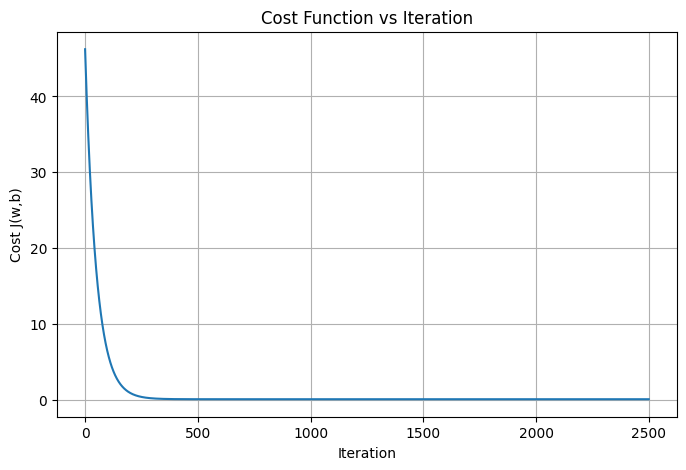

In [46]:
plt.figure(figsize=(8, 5))

plt.plot(cost_history)

plt.xlabel("Iteration")
plt.ylabel("Cost J(w,b)")
plt.title("Cost Function vs Iteration")

plt.grid(True)
plt.show()

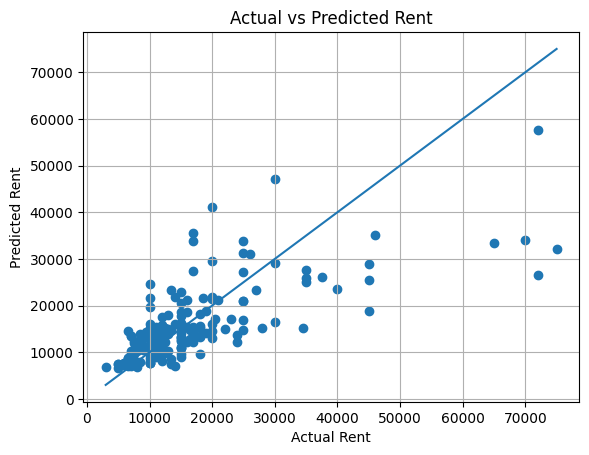

In [47]:
plt.scatter(y_test, test_pred)

minimum = min(y_test.min(), test_pred.min())
maximum = max(y_test.max(), test_pred.max())

plt.plot([minimum, maximum], [minimum, maximum])

plt.xlabel("Actual Rent")
plt.ylabel("Predicted Rent")
plt.title("Actual vs Predicted Rent")
plt.grid()
plt.show()

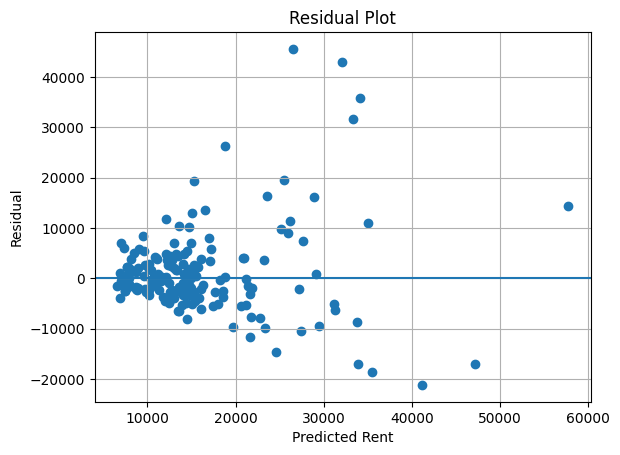

In [48]:
residuals = y_test - test_pred
plt.scatter(test_pred, residuals)

plt.axhline(0)

plt.xlabel("Predicted Rent")
plt.ylabel("Residual")
plt.title("Residual Plot")
plt.grid()
plt.show()

1> compare to see am i doing correct via sciket  #done
2> one hot encoding or target encoding on other columns
3> log on size
4> Benchmark with a tree model. Fit GradientBoostingRegressor or RandomForestRegressor